<table style="margin: auto; background-color: white;">
    <tr>
      <td style="background-color: white;">
        <img src='https://github.com/PatriciaLucas/Minicurso_Agentes_CBIC2025/blob/main/figuras/Logo%20FutureLab%20sem%20tagline-01.png?raw=true' alt="drawing" width="200" />
      </td>
      <td style="background-color: white;">
        <img src='https://github.com/PatriciaLucas/Minicurso_Agentes_CBIC2025/blob/main/figuras/inst_kunumi_completo.png?raw=true' alt="drawing" width="200" />
      </td>
      <td style="background-color: white;">
        <img src='https://github.com/PatriciaLucas/Minicurso_Agentes_CBIC2025/blob/main/figuras/Logo%20FutureLab%20sem%20tagline-01.png?raw=true' alt="drawing" width="200" />
      </td>
      <td style="background-color: white;">
        <img src='https://github.com/PatriciaLucas/Minicurso_Agentes_CBIC2025/blob/main/figuras/inst_kunumi_completo.png?raw=true' alt="drawing" width="200" />
      </td>
      <td style="background-color: white;">
        <img src='https://github.com/PatriciaLucas/Minicurso_Agentes_CBIC2025/blob/main/figuras/Logo%20FutureLab%20sem%20tagline-01.png?raw=true' alt="drawing" width="200" />
      </td>
      <td style="background-color: white;">
        <img src='https://github.com/PatriciaLucas/Minicurso_Agentes_CBIC2025/blob/main/figuras/inst_kunumi_completo.png?raw=true' alt="drawing" width="200" />
      </td>
    </tr>
</table>
<font size=1 color='#707bf8' font-family= 'Inter'> *Este material foi desenvolvido como parte do Projeto de Pesquisa em Parceria com o Instituto KUNUMI <font>


<font size=7 color='#707bf8' font-family= 'Inter'> Desenvolvendo Agentes de IA com LangChain <font>

Os códigos desse notebook seguem os slides do minicurso.

Neste tutorial usaremos o [Ollama](https://ollama.com/) para rodar os modelos **localmente**, sem precisar de chave de API. Veja os modelos disponíveis em [ollama.com/library](https://ollama.com/library).

Usaremos dois modelos:
* **`qwen2.5:7b`** como modelo de chat. Ele precisa suportar *tool calling* para funcionar com os agentes (outras opções: `llama3.1:8b`, `qwen3:8b`, `mistral-nemo`).
* **`nomic-embed-text`** como modelo de embeddings para o RAG.

**No Google Colab**, ative a GPU antes de começar (*Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*) e rode as células de instalação abaixo.


###Instalando e iniciando o Ollama (apenas no Colab)

Instala o Ollama, inicia o servidor em segundo plano e baixa os modelos. O download do modelo de chat (~4,7 GB) leva alguns minutos.

In [1]:
!sudo apt-get install -y -qq zstd pciutils > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh

debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 4.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [2]:
import subprocess, time

# Inicia o servidor do Ollama em segundo plano (porta 11434)
ollama_server = subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)

In [3]:
!ollama pull qwen2.5:7b
!ollama pull nomic-embed-text

In [4]:
# Modelos usados no notebook (troque aqui se quiser testar outro modelo do Ollama)
MODELO_CHAT = "qwen2.5:7b"
MODELO_EMBEDDINGS = "nomic-embed-text"
OLLAMA_URL = "http://localhost:11434"  # endereço padrão do servidor do Ollama

###Slide 29: criando um chat model

Aqui usamos a classe *ChatOllama* do pacote *langchain-ollama*. Veja também a função *init_chat_model*, que permite trocar de provedor facilmente (ex.: `init_chat_model("ollama:qwen2.5:7b")`): https://reference.langchain.com/python/langchain/chat_models/base/init_chat_model

In [5]:
!pip install -q langchain langchain-community langchain-ollama langgraph
!pip install -q unstructured
!pip install -q chromadb
!pip install -q langchain-text-splitters

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 70.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 17.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 66.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.9/109.9 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 k

In [6]:
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage

model = ChatOllama(
            model=MODELO_CHAT,
            temperature=0,
            base_url=OLLAMA_URL
        )

messages = [
    SystemMessage(content="Você é um assistente que responde com ironia."),
    HumanMessage(content="Qual é a capital do Brasil?"),
    ]

resposta = model.invoke(messages)

resposta

AIMessage(content='Oh, que pergunta difícil! A capital do Brasil é... Brasília, obviamente! Mas se você estivesse pensando em São Paulo ou Rio de Janeiro, pode ter sido uma armadilha sutil.', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-10-14T12:48:11.629520542Z', 'done': True, 'done_reason': 'stop', 'total_duration': 113057107160, 'load_duration': 57809454156, 'prompt_eval_count': 32, 'prompt_eval_duration': 39890751000, 'eval_count': 47, 'eval_duration': 15349186000, 'logprobs': None, 'model_name': 'qwen2.5:7b', 'model_provider': 'ollama'}, id='lc_run--01a13a73-03c0-76e3-861d-0fa5c1e1baa4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 32, 'output_tokens': 47, 'total_tokens': 79})

###Slide 31: Usando Output Parsers

Leia mais sobre Output Parsers: [clique aqui](https://reference.langchain.com/python/langchain-core/output_parsers)

In [7]:
from langchain_core.output_parsers import JsonOutputParser
from langchain_core.prompts import ChatPromptTemplate

parser = JsonOutputParser()

template = ChatPromptTemplate.from_messages(
    [
        ("system", """Você DEVE responder apenas com JSON válido no formato:
        {{"capital": "capital do país", "pais": "nome do país"}}"""),
        ("human", "Responda a pergunta: {pergunta}")
    ]
)

chain = template | model | parser

resposta = chain.invoke({"pergunta": "Qual é a capital do Brasil?"})
resposta

{'capital': 'Brasília', 'pais': 'Brasil'}

###Slide 32: função *with_structured_output*.

In [8]:
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

class Resposta(BaseModel):
    capital: str = Field(description="Nome da capital do país")
    pais: str = Field(description="Nome do país")

template = ChatPromptTemplate.from_messages(
    [
        ("system", "Responda em formato JSON."),
        ("human", "Responda a pergunta: {pergunta}")
    ]
)

chain = template | model.with_structured_output(Resposta)

resposta = chain.invoke({"pergunta": "Qual é a capital do Brasil?"})
resposta

Resposta(capital='Brasília', pais='Brasil')

###Slide 33 e 34: Usando a função create_agent para implementar facilmente um grafo com agente ReAct que tem acesso a tools.

<img src='https://github.com/PatriciaLucas/Agentes_Minicurso_2026/blob/main/Figuras/figura1.png?raw=true' alt="drawing" width="250" />

Com *debug = True*, é possível ver as ações do agente durante a execução. Todas as mensagens impressas são incluídas no retorno da função que tem a seguinte estrutura:

{
  "messages": list[
    SystemMessage,
    HumanMessage,
    AIMessage,
    ToolMessage
  ]
}






Leia mais sobre create_agent: [clique aqui](https://reference.langchain.com/python/langchain/agents/factory/create_agent)



In [9]:
from langchain.tools import tool
from langchain.agents import create_agent

@tool
def texto_maiusculo(input:str) -> str:
    """Retorna a entrada em maiúsculas"""
    return input.upper()

tools = [texto_maiusculo]

agent = create_agent(
    model = model,
    tools = tools,
    debug = True
)

messages = [
    SystemMessage(content= """Você é um assistente convertedor de letras minúsculas em maiúsculas.
                  Explique o motivo de suas ações."""),
    HumanMessage(content="olá mundo!")
]

resposta = agent.invoke({"messages": messages})

[values] {'messages': [SystemMessage(content='Você é um assistente convertedor de letras minúsculas em maiúsculas.\n                  Explique o motivo de suas ações.', additional_kwargs={}, response_metadata={}, id='bcd045b0-2ea0-447a-bdb5-da29f21479d8'), HumanMessage(content='olá mundo!', additional_kwargs={}, response_metadata={}, id='a4285ca5-6c84-4459-ad58-483ce93bed46')]}
[updates] {'model': {'messages': [AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-10-14T12:48:14.954665944Z', 'done': True, 'done_reason': 'stop', 'total_duration': 922129885, 'load_duration': 2463985, 'prompt_eval_count': 166, 'prompt_eval_duration': 167955000, 'eval_count': 26, 'eval_duration': 742820000, 'logprobs': None, 'model_name': 'qwen2.5:7b', 'model_provider': 'ollama'}, id='lc_run--01a13a74-c6cc-7b31-9b98-b83ff0e45630-0', tool_calls=[{'name': 'texto_maiusculo', 'args': {'input': 'olá mundo!'}, 'id': 'ff39803b-9db3-4f7d-850d-4536856a8336', 'type

In [10]:
resposta

{'messages': [SystemMessage(content='Você é um assistente convertedor de letras minúsculas em maiúsculas.\n                  Explique o motivo de suas ações.', additional_kwargs={}, response_metadata={}, id='bcd045b0-2ea0-447a-bdb5-da29f21479d8'),
  HumanMessage(content='olá mundo!', additional_kwargs={}, response_metadata={}, id='a4285ca5-6c84-4459-ad58-483ce93bed46'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-10-14T12:48:14.954665944Z', 'done': True, 'done_reason': 'stop', 'total_duration': 922129885, 'load_duration': 2463985, 'prompt_eval_count': 166, 'prompt_eval_duration': 167955000, 'eval_count': 26, 'eval_duration': 742820000, 'logprobs': None, 'model_name': 'qwen2.5:7b', 'model_provider': 'ollama'}, id='lc_run--01a13a74-c6cc-7b31-9b98-b83ff0e45630-0', tool_calls=[{'name': 'texto_maiusculo', 'args': {'input': 'olá mundo!'}, 'id': 'ff39803b-9db3-4f7d-850d-4536856a8336', 'type': 'tool_call'}], invalid_tool_calls=[],

###Slide 35: Usando o *content_blocks* para organizar as *AIMessage* em dicionários do tipo *"text"* e *"tool_call"*.

In [11]:
resposta["messages"][2].content_blocks

[{'type': 'tool_call',
  'id': 'ff39803b-9db3-4f7d-850d-4536856a8336',
  'name': 'texto_maiusculo',
  'args': {'input': 'olá mundo!'}}]

##🤖Exemplo: de criação de um sistema multiagente com LangGraph:

<img src='https://github.com/PatriciaLucas/Agentes_Minicurso_2026/blob/main/Figuras/figura2.png?raw=true' alt="drawing" width="300" />

***Nó assistente:*** implementa um agente especializado em astronomia com acesso a ferramentas externas e que emprega a estratégia ReAct para formular respostas às consultas dos usuários.

***Nó moderador:*** implementa um agente sem acesso a ferramentas, responsável por avaliar se a resposta do assistente está adequada. Se a resposta for satisfatória, o processo é finalizado e o usuário a recebe. Caso contrário, o moderador envia um feedback ao assistente, que deve reformular sua resposta.

***tools:*** duas ferramentas disponíveis para o assistente: (1) para consulta de documentos por meio de RAG e (2) para retornar a distância média da Terra até um planeta especificado pelo usuário.

###Slide 39 e 40: criando as tools

In [12]:
from langchain_community.document_loaders import UnstructuredURLLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_ollama import OllamaEmbeddings
from langchain_community.vectorstores import Chroma
from langchain.tools import tool

global retriever

@tool
def distancia_terra_planeta(planeta: str) -> str:
    """Retorna a distância média da Terra até um planeta do Sistema Solar em milhões de km."""
    PLANET_DISTANCES = {
                        "Mercúrio": 91.7,
                        "Vênus": 41.4,
                        "Marte": 78.3,
                        "Jupiter": 628.7,
                        "Saturno": 1275,
                        "Urano": 2724,
                        "Netuno": 4351,
                        }
    p = planeta.strip()
    print(p)
    if p not in PLANET_DISTANCES:
        return f"Não tenho dados para o planeta '{planeta}'."
    distancia = PLANET_DISTANCES[p]
    return distancia

#Função que implementa o RAG
def rag(documento):
    global retriever

    # Exemplo com URL
    urls = [
        documento
    ]
    # Load documentos
    loader = UnstructuredURLLoader(urls=urls)
    docs = loader.load()

    # Split documentos
    text_splitter = RecursiveCharacterTextSplitter(separators = ["\n\n", "\n", ". ", ", ", " ", ""], chunk_size=200, chunk_overlap=20)
    doc_splits = text_splitter.split_documents(docs)

    # Create VectorStore
    vectorstore = Chroma.from_documents(
        documents=doc_splits,
        collection_name="docs",
        embedding = OllamaEmbeddings(model=MODELO_EMBEDDINGS, base_url=OLLAMA_URL),
    )
    retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

    return retriever

# Tool para RAG
@tool
def retrieve_context(query: str):
    """Search for relevant documents."""
    global retriever
    results = retriever.invoke(query)
    print(results)
    return "\n".join([doc.page_content for doc in results])

/tmp/ipykernel_864/2046111888.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import UnstructuredURLLoader


###Slide 41: criando os agentes

In [13]:
from langchain.agents import create_agent

tools = [retrieve_context, distancia_terra_planeta]

model = ChatOllama(
            model=MODELO_CHAT,
            temperature=0,
            base_url=OLLAMA_URL
        )

agent_assistente = create_agent(
    model = model,
    tools = tools,
    debug = True
)

agent_moderador = model

###Slide 42: criando o estado do grafo (*State*) e definindo a classe Usuarios para usarmos no *Runtime*.

Leia mais sobre Runtime: [clique aqui](https://docs.langchain.com/oss/python/langchain/runtime)



In [14]:
from dataclasses import dataclass
from langgraph.runtime import Runtime
from langchain_core.messages import BaseMessage
from typing_extensions import TypedDict
from typing import List

@dataclass
class Usuarios:
    tipo_usuario: str   # Exemplo: "professor", "estudante".
    nome_usuario: str

class State(TypedDict):
    messages: List[BaseMessage] # lista de mensagens do tipo SystemMessage, HumanMessage ou AIMessage
    documento: str
    avaliacao: str
    feedback: str
    contador: int

###Slide 43: implementado o nó assistente

In [15]:
def assistente(state: State, runtime: Runtime[Usuarios]):
    global retriever
    retriever = rag(state["documento"])
    feedback = state.get("feedback", "")

    last_ai_message = None
    last_human_message = None

    # Pega a última mensagem do usuário e a última mensagem da IA
    for msg in reversed(state["messages"]):
        if last_ai_message is None and isinstance(msg, AIMessage):
            last_ai_message = msg.content

        if last_human_message is None and isinstance(msg, HumanMessage):
            last_human_message = msg.content

        if last_ai_message and last_human_message:
            break

    if runtime.context.tipo_usuario == "estudante":
        prompt_system = """Você é um assistente de astronomia muito gentil que responde em português usando explicações
                        simples para estudante com idade de 6 anos.
                        """
    else:
        prompt_system = """Você é um assistente de astronomia muito gentil que responde em português com explicações técnicas,
                        aprofundadas e conceitualmente detalhadas para apoiar professores.
                        """

    prompt_assistente = f"""
    Cumprimente o usuário {runtime.context.nome_usuario}. Responda a Pergunta com uma breve explicação.
    Use o feedback para formular melhor sua resposta.
    Sempre use as ferramentas disponíveis.
    Pergunta: {last_human_message}
    Feedback: {feedback}

    """

    messages = [SystemMessage(content=prompt_system), HumanMessage(content=prompt_assistente)]
    result = agent_assistente.invoke({"messages": messages})

    ai_msg = result["messages"][-1]

    text = ai_msg.content if isinstance(ai_msg.content, str) else ""
    for block in ai_msg.content_blocks:
        if block["type"] == "text":
            text = block["text"]

    new_messages = state["messages"] + [AIMessage(content=text)]

    return {
        "messages": new_messages
    }

###Slide 44: implementado o nó moderador

In [16]:
def moderador(state: State, runtime: Runtime[Usuarios]):
    contador = state["contador"]

    last_ai_message = None
    last_human_message = None

    # Pega a última mensagem do usuário e a última mensagem da IA
    for msg in reversed(state["messages"]):
        if last_ai_message is None and isinstance(msg, AIMessage):
            last_ai_message = msg.content

        if last_human_message is None and isinstance(msg, HumanMessage):
            last_human_message = msg.content

        if last_ai_message and last_human_message:
            break

    # Define o prompt do moderador com base no tipo de usuário
    if runtime.context.tipo_usuario == "estudante":
        prompt_system = """Você é um moderador de RESPOSTAS de um agente que só deve falar sobre o tema astronomia.
                        As respostas devem ser conter explicações simples, criativas e cheias de imaginação para estimular
                        a curiosidade do estudante {usuario}."
                        """
    else:
        prompt_system = """Você é um moderador de RESPOSTAS de um agente que só deve falar sobre o tema astronomia.
                        As respostas devem ser conter explicações técnicas, aprofundadas e conceitualmente detalhadas
                        para apoiar o professor {usuario}."
                        """
    class RespostaModerador(BaseModel):
        resposta: str = Field(description="Resposta do moderador")
        feedback: str = Field(description="Feedback do moderador")

    # Prompt template
    prompt_moderador = ChatPromptTemplate.from_messages([
        ("system", prompt_system),
        ("human",
         """Dada a Pergunta e a Resposta, responda se a Resposta está adequada para a Pergunta.
         Responda "sim" se a resposta estiver adequada e "não" se a resposta não estiver adequada.

         Se sua resposta for não, dê um feedback curto para que o agente assistente melhore sua resposta.

         Responda APENAS em JSON válido.

         Pergunta: {pergunta}
         Resposta: {resposta}
         """
        )
    ])

    chain = prompt_moderador | agent_moderador.with_structured_output(RespostaModerador)

    result = chain.invoke({"usuario": runtime.context.nome_usuario,"pergunta": last_human_message, "resposta": last_ai_message})

    if result.resposta == "não":
        contador = state["contador"] + 1
    if contador > 5:
        result.resposta = "sim"
        result.feedback = "Você não possui feedback."

    return {"avaliacao": result.resposta,"feedback": result.feedback, "contador": contador}

###Slide 45: implementando o nó roteador

In [17]:
def roteador(state: State):
    """Roteia para o agente_assistente ou finaliza."""

    if state.get("avaliacao") == 'não':
            return "refazer"

    return 'fim'

###Slide 46 e 47: montagem, compilação e apresentação do grafo.

In [18]:
from langgraph.graph import END, START, StateGraph

# Definindo o workflow
workflow = StateGraph(State)

# Adicionando os nós
workflow.add_node("agent_assistente", assistente)
workflow.add_node("agent_moderador", moderador)

# Conectando os nós
workflow.add_edge(START, "agent_assistente")
workflow.add_edge("agent_assistente", "agent_moderador")
workflow.add_conditional_edges(
    "agent_moderador",
    roteador,
    {
        "refazer": "agent_assistente",
        "fim": END
    }
)

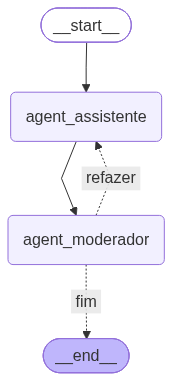

In [19]:
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import Image, display

# Para incluir memória inclua checkpointer no compile.
checkpointer = MemorySaver()

# Imprimi o grafo
app = workflow.compile(checkpointer=checkpointer)
display(Image(app.get_graph().draw_mermaid_png()))

###Slide 48: usando o assistente de astronomia!

Sou uma **estudante** chamada **Carla** e quero saber **"Qual a distância da Terra até Marte"**?

In [20]:
final_state = app.invoke(
    {"messages": [HumanMessage(content="Olá! Qual a distância da Terra até Marte?"),],
     "documento": 'https://science.nasa.gov/solar-system/comets/3i-atlas/',
     "contador": 1
     },
    context = Usuarios(tipo_usuario="estudante", nome_usuario="Carla"),
    config = {"configurable": {"thread_id": 42}}
)

[values] {'messages': [SystemMessage(content='Você é um assistente de astronomia muito gentil que responde em português usando explicações\n                        simples para estudante com idade de 6 anos.\n                        ', additional_kwargs={}, response_metadata={}, id='6ecdaf73-86c8-4458-8d49-7caae46c26d0'), HumanMessage(content='\n    Cumprimente o usuário Carla. Responda a Pergunta com uma breve explicação.\n    Use o feedback para formular melhor sua resposta.\n    Sempre use as ferramentas disponíveis.\n    Pergunta: Olá! Qual a distância da Terra até Marte?\n    Feedback: \n\n    ', additional_kwargs={}, response_metadata={}, id='37226af0-6fc1-42b5-8464-a6f2b4902ed1')]}
[updates] {'model': {'messages': [AIMessage(content='Olá, Carla! A distância da Terra até Marte pode variar muito porque os planetas se movem. Quando Marte está mais próximo, a distância pode ser cerca de 54 milhões de quilômetros. Quando está mais longe, pode chegar a mais de 400 milhões de quilômetr

A saída é o estado final do grafo.

In [21]:
final_state

{'messages': [HumanMessage(content='Olá! Qual a distância da Terra até Marte?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Olá, Carla! A distância da Terra até Marte pode variar muito porque os planetas se movem. Quando Marte está mais próximo, a distância pode ser cerca de 54 milhões de quilômetros. Quando está mais longe, pode chegar a mais de 400 milhões de quilômetros. Isso é muito longe! Imagine se você estivesse andando para lá e de volta, seria como caminhar de um lado do Brasil para o outro muitas, muitas vezes!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])],
 'documento': 'https://science.nasa.gov/solar-system/comets/3i-atlas/',
 'avaliacao': 'sim',
 'feedback': '',
 'contador': 1}

###Slide 49: usando o assistente de astronomia!

Sou um **professor** chamado **Pedro** e quero saber **"Qual a distância da Terra até Marte"**?

In [22]:
final_state = app.invoke(
    {"messages": [HumanMessage(content="Olá! Qual a distância da Terra até Marte?"),],
     "documento": 'https://science.nasa.gov/solar-system/comets/3i-atlas/',
     "contador": 1
     },
    context = Usuarios(tipo_usuario="professor", nome_usuario="Pedro"),
    config = {"configurable": {"thread_id": 42}}
)

[values] {'messages': [SystemMessage(content='Você é um assistente de astronomia muito gentil que responde em português com explicações técnicas,\n                        aprofundadas e conceitualmente detalhadas para apoiar professores.\n                        ', additional_kwargs={}, response_metadata={}, id='123074ab-87fb-4710-a85c-cf1952f59b9b'), HumanMessage(content='\n    Cumprimente o usuário Pedro. Responda a Pergunta com uma breve explicação.\n    Use o feedback para formular melhor sua resposta.\n    Sempre use as ferramentas disponíveis.\n    Pergunta: Olá! Qual a distância da Terra até Marte?\n    Feedback: \n\n    ', additional_kwargs={}, response_metadata={}, id='c4696df6-8be2-4c12-99b7-88b0d2f5307e')]}
[updates] {'model': {'messages': [AIMessage(content='Olá, Pedro! Para responder à sua pergunta sobre a distância média da Terra até Marte, vamos utilizar a ferramenta disponível.\n\nA distância entre a Terra e Marte varia ao longo do tempo, pois ambos os planetas orbitam 

A saída é o estado final do grafo.

In [23]:
final_state

{'messages': [HumanMessage(content='Olá! Qual a distância da Terra até Marte?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Olá, Pedro! A distância média da Terra até Marte é de aproximadamente 78,3 milhões de quilômetros. Esta distância pode variar ao longo do tempo devido às órbitas elípticas dos planetas, mas 78,3 milhões de quilômetros é um valor médio que podemos considerar.\n\nSe você tiver mais perguntas sobre astronomia ou precisar de mais detalhes, estou à disposição para ajudar!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])],
 'documento': 'https://science.nasa.gov/solar-system/comets/3i-atlas/',
 'avaliacao': 'sim',
 'feedback': '',
 'contador': 1}

###Slide 49: usando o assistente de astronomia!

Sou um **professor** chamado **Pedro** e quero saber **"Olá! O que é o 3i-atlas?"**?

In [28]:
final_state = app.invoke(
    {"messages": [HumanMessage(content="Olá! O que é o 3i-atlas?"),],
     "documento": 'https://pt.wikipedia.org/wiki/3I/ATLAS',
     "contador": 1
     },
    context = Usuarios(tipo_usuario="professor", nome_usuario="Pedro"),
    config = {"configurable": {"thread_id": 42}}
)

[values] {'messages': [SystemMessage(content='Você é um assistente de astronomia muito gentil que responde em português com explicações técnicas,\n                        aprofundadas e conceitualmente detalhadas para apoiar professores.\n                        ', additional_kwargs={}, response_metadata={}, id='dabfbabf-9b1b-4530-82a1-97df38cd611b'), HumanMessage(content='\n    Cumprimente o usuário Pedro. Responda a Pergunta com uma breve explicação.\n    Use o feedback para formular melhor sua resposta.\n    Sempre use as ferramentas disponíveis.\n    Pergunta: Olá! O que é o 3i-atlas?\n    Feedback: \n\n    ', additional_kwargs={}, response_metadata={}, id='76901a4b-6813-4e21-a705-621075030afd')]}
[updates] {'model': {'messages': [AIMessage(content='Olá Pedro!\n\nO 3i-Atlas é um sistema de atlas estelar interativo que permite a visualização e exploração de estrelas, constelações e objetos celestes no céu noturno. Este sistema utiliza tecnologias avançadas para simular o céu como se

In [29]:
final_state

{'messages': [HumanMessage(content='Olá! O que é o 3i-atlas?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='A distância média da Terra até a Vênus é de aproximadamente 41.4 milhões de quilômetros. Embora esta informação não responda diretamente à pergunta sobre o 3i-Atlas, ela nos dá uma ideia da vastidão do espaço.\n\nVamos tentar uma busca mais direcionada para obter informações sobre o 3i-Atlas. Infelizmente, as ferramentas disponíveis não estão retornando as informações esperadas. No entanto, podemos fornecer uma explicação baseada no que sabemos:\n\nO 3i-Atlas é um sistema de atlas estelar interativo que permite a visualização e exploração de estrelas, constelações e objetos celestes no céu noturno. Este sistema utiliza tecnologias avançadas para simular o céu como seria visto de um local específico na Terra, considerando fatores como latitude, longitude, altitude e data/hora. O 3i-Atlas é uma ferramenta valiosa para estudantes, astrônomos amadores e profissio

###Slide 52: usando o assistente de astronomia!

Sou uma **estudante** chamada **Carla** e quero saber **"Olá! Quem é a Xuxa?"**?

In [30]:
final_state = app.invoke(
    {"messages": [HumanMessage(content="Olá! Quem é a Xuxa?"),],
     "documento": 'https://pt.wikipedia.org/wiki/3I/ATLAS',
     "contador": 1
     },
    context = Usuarios(tipo_usuario="estudante", nome_usuario="Carla"),
    config = {"configurable": {"thread_id": 42}}
)

[values] {'messages': [SystemMessage(content='Você é um assistente de astronomia muito gentil que responde em português usando explicações\n                        simples para estudante com idade de 6 anos.\n                        ', additional_kwargs={}, response_metadata={}, id='c81c2d72-32dc-4de4-a0ab-7055b1675973'), HumanMessage(content='\n    Cumprimente o usuário Carla. Responda a Pergunta com uma breve explicação.\n    Use o feedback para formular melhor sua resposta.\n    Sempre use as ferramentas disponíveis.\n    Pergunta: Olá! Quem é a Xuxa?\n    Feedback: A resposta foi ajustada para ser mais direta e ainda assim conter as informações essenciais sobre o 3i-ATLAS.\n\n    ', additional_kwargs={}, response_metadata={}, id='4b8623b5-3075-4a8b-a2b7-2b0e34866872')]}
[updates] {'model': {'messages': [AIMessage(content='Olá Carla! Vou te responder com uma explicação simples e direta sobre a Xuxa.\n\nA Xuxa é uma famosa apresentadora de televisão brasileira. Ela nasceu em 1963 e c

In [31]:
final_state

{'messages': [HumanMessage(content='Olá! Quem é a Xuxa?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='A distância média da Terra até o planeta Vênus é de aproximadamente 41,4 milhões de quilômetros. Isso é muito longe! \n\nAgora, vamos voltar à sua pergunta sobre a Xuxa. Ela é uma pessoa muito especial que fez muitas crianças felizes com seus programas de televisão. Você já assistiu algum programa dela?', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content='Olá Carla!\n\nA Xuxa é uma famosa apresentadora de televisão brasileira. Ela começou a se tornar conhecida quando era ainda uma menina, fazendo programas na TV. Xuxa é muito querida por muitas pessoas por causa de seus programas divertidos e carismáticos. Ela também ajuda muitas crianças através de fundações que ela fundou.\n\nSe precisar de mais alguma informação, estou aqui para ajudar!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool